# NLRB union elections — exploratory data analysis

Loads the `analytical_elections` view (RC/RM filings) and profiles the two
modeling targets: the regression target `vote_ratio` and the classification
target `success`.

In [ ]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime

with duckdb.connect("../data/union_elections.duckdb", read_only=True) as con:
    df = con.execute("SELECT * FROM analytical_elections").fetchdf()
print(df.columns)
print(df.shape)
df.head()

Index(['case_number', 'case_type', 'city', 'state', 'date_filed',
       'date_closed', 'reason_closed', 'election_id', 'tally_type',
       'unit_size', 'election_date', 'more_than_one_election',
       'votes_for_union', 'votes_against', 'rpt_id', 'yr_covered',
       'pd_covered_from', 'pd_covered_to', 'f_num', 'desig_num', 'terminate',
       'representational', 'political', 'contributions', 'general_overhead',
       'union_administration', 'employer_name', 'region_assigned',
       'filing_status', 'filing_number_of_eligible_voters',
       'number_of_voters_on_petition_or_charge', 'certified_representative',
       'ballot_type', 'voting_unit_id', 'finance_union_name',
       'finance_aff_abbr', 'members', 'form_type', 'ttl_receipts',
       'ttl_disbursements', 'election_union_name', 'union_participant',
       'union_participant_type', 'pred_union_name', 'pred_f_num',
       'pred_f_num_score', 'pred_is_union', 'pred_union_name_score',
       'pred_is_union_score'],
      dtyp

,case_number,case_type,city,state,date_filed,date_closed,reason_closed,election_id,tally_type,unit_size,...,ttl_disbursements,election_union_name,union_participant,union_participant_type,pred_union_name,pred_f_num,pred_f_num_score,pred_is_union,pred_union_name_score,pred_is_union_score
0,18-RC-017670,RC,Waterloo,IA,2009-11-24,2010-01-19,Certification of Results,22467,Initial,404,...,2553029,"UNITED AUTOMOBILE WORKERS, LOCAL 838","UNITED AUTOMOBILE WORKERS, LOCAL 838",Union,AUTO WORKERS AFL-CIO,2232,0.9913,1,0.9974,0.9683
1,06-RC-012714,RC,Duncansville,PA,2009-12-04,2010-01-20,Certific. of Representative,6038,Initial,9,...,2158902,INTERNATIONAL UNION OF PAINTERS AND ALLIED TRA...,INTERNATIONAL UNION OF PAINTERS AND ALLIED TRA...,Union,PAINTERS AFL-CIO,540940,0.9812,1,0.9937,0.9611
2,25-RC-010486,RC,Columbia City,IN,2010-01-05,2010-02-23,Certific. of Representative,17593,Initial,14,...,1142069,"TEAMSTERS LOCAL NO. 414, AFFILIATED WITH THE I...","TEAMSTERS LOCAL NO. 414, AFFILIATED WITH THE I...",Union,TEAMSTERS,17875,0.9928,1,0.9982,0.9769
3,29-RC-011841,RC,Brooklyn,NY,2009-12-22,2010-01-29,Certification of Results,19213,Initial,79,...,41643,Grandpa Bus Company,Grandpa Bus Company,Union,"UNITED SERVICE WORKERS UNION, IUJAT",517592,0.0304,0,0.0870,0.0021
4,19-RC-015325,RC,Seattle,WA,2010-06-22,2010-08-06,Certific. of Representative,13649,Initial,12,...,9848442,INTERNATIONAL BROTHERHOOD OF TEAMSTERS LOCAL U...,INTERNATIONAL BROTHERHOOD OF TEAMSTERS LOCAL U...,Union,TEAMSTERS,5960,0.9956,1,0.9958,0.9402


## Case types, uniqueness

Confirming that the view is one row per election (one completed RC/RM case each).

In [4]:
print("rows:", len(df))
print("distinct filings:", df["case_number"].nunique())
print("distinct elections:", df["election_id"].nunique())
print()
df["case_type"].value_counts()

rows: 22196
distinct filings: 22196
distinct elections: 22196



case_type
RC    21598
RM      598
Name: count, dtype: int64

## Closing reason and the success label

An election is treated as successful when
`reason_closed == 'Certific. of Representative'`.

In [28]:
df["reason_closed"].value_counts(dropna=False)

reason_closed
Certific. of Representative    15170
Certification of Results        6615
Withdrawal Non-adjusted          339
Dismissal Non-adjusted            32
Withdrawal Adjusted               28
Administrative Closing             4
Amended Certification              4
Compliance w/BO                    2
Unit Clarification                 1
Dismissal Adjusted                 1
Name: count, dtype: int64

In [5]:
df["success"] = (
    df["reason_closed"]
    .map(lambda value: pd.NA if pd.isna(value) else int(value == "Certific. of Representative"))
    .astype("Int64")
)
print(df["success"].value_counts(dropna=False))

print(f'The fraction of rows that are success is {sum(df["success"]) / len(df)}')

success
1    15170
0     7026
Name: count, dtype: Int64
The fraction of rows that are success is 0.6834564786448009


Relatively mild class imbalance since there are still ~7000 cases that did not succeed.

## Target Variable: Vote net margin

`net_margin= votes_for_union - votes_against / <total_votes_cast>`.

votes_against or votes_for = null mean 0 votes.


In [61]:
df[['votes_for_union', 'votes_against']] = df[['votes_for_union', 'votes_against']].where(
    df[['votes_for_union', 'votes_against']].notna(), 0
)
df['total'] = df[['votes_for_union', 'votes_against']].apply(sum, axis=1)

df['net_margin'] = (df['votes_for_union'] - df['votes_against']) / df['total']

df["net_margin"].describe()



count     22102.0
mean     0.361165
std      0.550494
min          -1.0
25%     -0.043478
50%      0.428571
75%      0.888889
max           1.0
Name: net_margin, dtype: Float64

Text(0, 0.5, '# of elections')

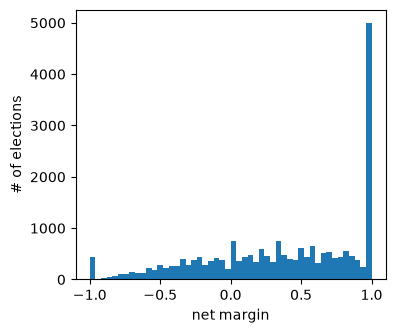

In [62]:
plt.figure(figsize=(4, 3.5))
plt.hist(df['net_margin'], bins=50)
plt.xlabel('net margin')
plt.ylabel('# of elections')

## Missingness

In [7]:
df.isna().mean().sort_values(ascending=False).head(30)

certified_representative            0.538385
filing_number_of_eligible_voters    0.349207
desig_num                           0.281177
general_overhead                    0.252478
political                           0.252478
union_administration                0.252478
representational                    0.252478
votes_against                       0.225176
contributions                       0.168544
terminate                           0.155028
ttl_receipts                        0.135925
pd_covered_from                     0.135880
yr_covered                          0.135880
pd_covered_to                       0.135880
f_num                               0.135880
rpt_id                              0.135880
finance_aff_abbr                    0.135880
finance_union_name                  0.135880
form_type                           0.135880
ttl_disbursements                   0.135880
votes_for_union                     0.023473
pred_is_union                       0.018472
pred_union

## Other Election Variables

- Days from filing to election
- Turnout

28 cases with 0 days between filing and election


/home/peishi/machine-learning-zoomcamp/union-elections-modeling/.venv/lib/python3.13/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


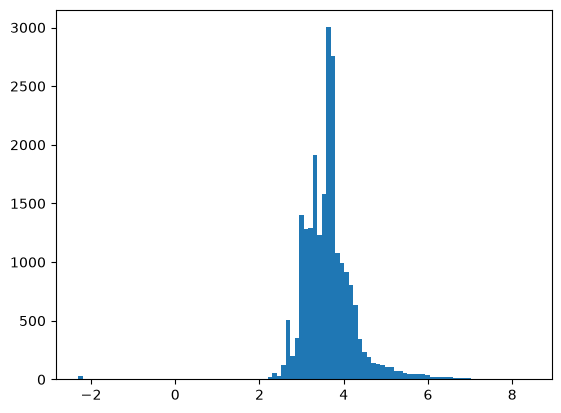

In [89]:
df['days_to_election'] = (df['election_date'] - df['date_filed']).apply(
    lambda x: int( x / datetime.timedelta(days=1) ) if pd.notna(x) else x
)

# Miscoded data. Checked 05-RC-244804 and 13-RC-090072 and dates seem like typos.
# df[df['days_to_election'] < 0][['election_date', 'date_filed', 'case_number']]

df['days_to_election'].describe()

# Need to take log of these since many extreme values. Any elections with 0 days between filing and election?
print(f"{sum(df['days_to_election'] == 0)} cases with 0 days between filing and election")

plt.hist(np.log(df['days_to_election'] + 0.1), bins=100)
plt.show()

Number of elections with turnout >1 is 119


(array([3.000e+00, 0.000e+00, 3.000e+00, 5.000e+00, 2.000e+00, 4.000e+00,
        6.000e+00, 4.000e+00, 4.000e+00, 5.000e+00, 7.000e+00, 1.000e+01,
        6.000e+00, 1.400e+01, 1.100e+01, 1.100e+01, 2.200e+01, 1.900e+01,
        3.000e+01, 2.600e+01, 3.200e+01, 3.700e+01, 4.700e+01, 5.100e+01,
        6.700e+01, 5.300e+01, 5.800e+01, 6.700e+01, 7.400e+01, 1.030e+02,
        9.200e+01, 1.400e+02, 1.070e+02, 2.070e+02, 1.890e+02, 2.280e+02,
        2.120e+02, 3.120e+02, 3.080e+02, 3.700e+02, 3.570e+02, 5.030e+02,
        5.760e+02, 6.060e+02, 7.520e+02, 7.180e+02, 7.770e+02, 7.720e+02,
        5.750e+02, 2.468e+03]),
 array([0.01675978, 0.03642458, 0.05608939, 0.07575419, 0.09541899,
        0.1150838 , 0.1347486 , 0.15441341, 0.17407821, 0.19374302,
        0.21340782, 0.23307263, 0.25273743, 0.27240223, 0.29206704,
        0.31173184, 0.33139665, 0.35106145, 0.37072626, 0.39039106,
        0.41005587, 0.42972067, 0.44938547, 0.46905028, 0.48871508,
        0.50837989, 0.52804469, 0.54

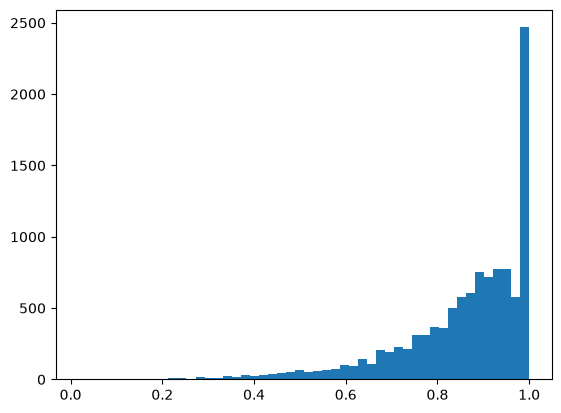

In [15]:
# Turnout

nonzero = df['filing_number_of_eligible_voters'] > 0
df['total_votes'] = df['votes_for_union'] + df['votes_against']
df.loc[nonzero, 'turnout'] = df.loc[nonzero, 'total_votes'] / df.loc[nonzero, 'filing_number_of_eligible_voters']

# Number of elections with turnout greater than 1
print(f"Number of elections with turnout >1 is {sum(df[df['turnout'].notna()]['turnout'] > 1)}")
df[df['turnout'] > 1][['total_votes', 'filing_number_of_eligible_voters']]

invalid = df['turnout'] > 1
df.loc[invalid, 'turnout'] = None

plt.hist(df['turnout'], bins=50)

In [8]:
# There are a lot of rows missing the filing_number_of_eligible_voters column

pct_diff = (df['unit_size'] - df['filing_number_of_eligible_voters'] ) / df['unit_size']

pct_diff.describe()

# Number of elections where the two numbers differ. 
n_diff = sum(
    df[['unit_size', 'filing_number_of_eligible_voters']].apply(
        lambda x: x['unit_size'] == x['filing_number_of_eligible_voters'] if all(x.notna()) else False, axis=1
    )
)

print(f"Number of elections where eligible == unit size: {n_diff} out of {sum(df['filing_number_of_eligible_voters'].notna())}")

df[df['unit_size'] != df['filing_number_of_eligible_voters']][['case_number', 'filing_number_of_eligible_voters', 'unit_size']]

Number of elections where eligible == unit size: 14263 out of 14445


,case_number,filing_number_of_eligible_voters,unit_size
79,17-RC-012650,37,35
162,19-RC-202745,160,165
183,27-RC-207306,5,2
259,04-RC-021754,3,18
324,29-RC-011882,3,5
...,...,...,...
21564,26-RC-008635,358,6
21580,19-RC-235545,215,213
21698,15-RC-204708,87,71
22096,05-RC-212240,8,9


## LM Report and Finances

In [8]:
(
    df.groupby("form_type", dropna=False)
        .agg(
            rows=("case_number", "size"),
            median_disbursements=("ttl_disbursements", "median"),
            median_receipts=("ttl_receipts", "median"),
        )
        .sort_values("rows", ascending=False)
)

,rows,median_disbursements,median_receipts
form_type,,,
LM-2,16592,5030522.5,5141985.0
NaN,3016,<NA>,<NA>
LM-3,1903,46689.0,56914.0
LM-4,685,500.0,872.0


### Union Size

In [9]:
unions = df.drop_duplicates(subset='f_num').dropna(subset='members')
unions['members'].describe()

count          2344.0
mean      4872.561007
std      26670.480735
min               0.0
25%             287.5
50%            1007.0
75%           2966.25
max          848323.0
Name: members, dtype: Float64

In [ ]:
# Largest unions. Different member numbers for same union because depending on the year of the LM report, has different number of members.

unions[unions['members']>1e5][['pred_union_name', 'members']].sort_values(by='members', ascending=False)

,pred_union_name,members
14124,TEACHERS AFL-CIO,848323
1699,TEACHERS AFL-CIO,663681
542,SERVICE EMPLOYEES,369933
1716,STATE COUNTY AND MUNI EMPLS AFL-CIO,228086
803,"SHEET METAL, AIR, RAIL AND TRANSPORTATION WORKERS",203280
1721,TEACHERS AFL-CIO,192518
780,SERVICE EMPLOYEES,188129
14979,TEAMSTERS,146464
1809,NATIONAL EDUCATION ASN IND,132940
11740,TEAMSTERS,113506


Text(0, 0.5, 'Number of unions ')

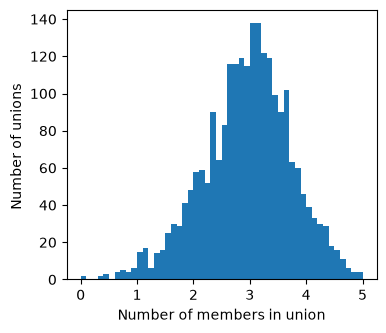

In [ ]:
# Distribution of union sizes for unique unions in the dataset

plt.figure(figsize=(4, 3.5))
plt.hist(unions['members'].apply(np.log10), bins=50, range=[0, 5])
plt.xlabel('Log 10 number of members in union')
plt.ylabel('Number of unions ')

Text(0, 0.5, 'Number of elections with union of that size')

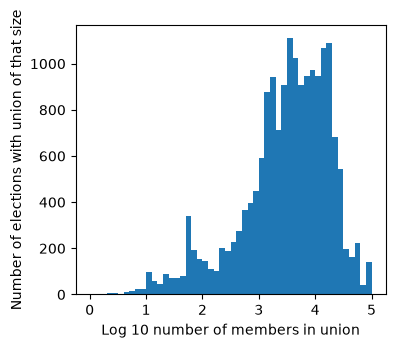

In [ ]:
# Distribution of union sizes based on counts of unions by election.

plt.figure(figsize=(4, 3.5))
plt.hist(df['members'].apply(np.log10), bins=50, range=[0, 5])
plt.xlabel('Log 10 number of members in union')
plt.ylabel('Number of elections with union of that size')

Seems like elections tend to have larger unions as participants (larger as compared to distribution of unique unions in dataset)

**Make sure to use the log of the number of members as the feature**

### Union disbursements

Only forms LM2 report total disbursements by category of representational/political activities. Consider only these for now.

In [47]:
# How many rows have the right report type
df['form_type'].value_counts()

form_type
LM-2    16592
LM-3     1903
LM-4      685
Name: count, dtype: int64

In [ ]:
valid_rows = df[['ttl_disbursements', 'representational', 'political', 'members']].apply(
    lambda row: all([pd.notna(x) for x in row]), axis=1
)

print(f"{sum(valid_rows)} out of {len(df)} rows in df have non-null for relevant finance cols")

16397 out of 22196 rows in df have non-null for relevant finance cols


In [11]:
# Generate finance data

fin = unions.dropna(subset=['ttl_disbursements', 'representational', 'political', 'members'])

nonzero = (fin['ttl_disbursements'] != 0) & (fin['members'] != 0)

fin = fin[nonzero]

Median fraction of disbursements on representational: 0.27060660862310604


count      1637.0
mean     0.271741
std      0.133232
min           0.0
25%      0.183868
50%      0.270607
75%      0.347092
max      0.980767
Name: rep_frac, dtype: Float64

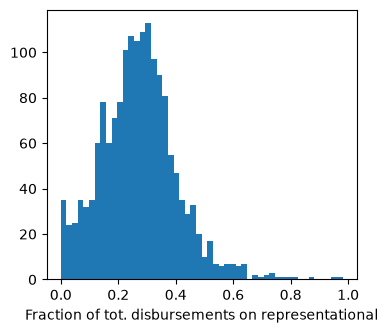

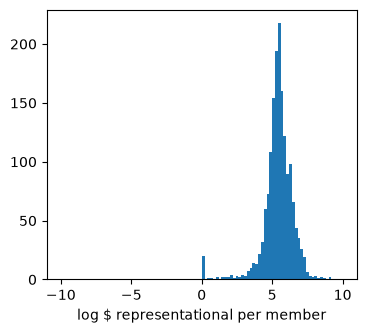

In [ ]:
# Representational spending

fin['rep_frac'] = fin['representational'] / fin['ttl_disbursements']
fin['rep_per_mem'] = fin['representational'] / fin['members']
fin['log_rep_per_mem'] = np.log(fin['rep_per_mem'] + 1)

print(f"Median fraction of disbursements on representational: {np.median(fin['rep_frac'])}")

plt.figure(figsize=(4, 3.5))
plt.hist(fin['rep_frac'], bins=50)
plt.xlabel('Fraction of tot. disbursements on representational')
plt.figure(figsize=(4, 3.5))
plt.hist(fin['log_rep_per_mem'], bins=100, range=[-10, 10])
plt.xlabel('log $ representational per member')
fin['rep_frac'].describe()

### Outliers on spending per member

Some of these are larger national or regional bodies where most of the disbursements are made. Since there are so few, just exclude these outliers.

One method to handle this could be aggregating all of the unions by their affiliations and summing all of the total disbursements and then dividing by total members to get an average of representational spending by union. Not sure if this averages out too much granularity

Also, we could take the log of 

In [47]:
fin[fin['rep_per_mem'] > 3000][['representational', 'members', 'rep_per_mem', 'union_participant', 'rpt_id', 'f_num']].sort_values('rep_per_mem', ascending=False)

,representational,members,rep_per_mem,union_participant,rpt_id,f_num
1558,3693063,15,246204.2,LABORERS' INTERNATIONAL UNION OF NORTH AMERICA,452182,31618
2551,1714691,11,155881.0,MID CENTRAL ILLINOIS REGIONAL COUNCIL OF CARPE...,464969,509324
3137,817641,11,74331.0,Public Service Employees Local Union - LIUNA,475423,8146
6415,1241607,24,51733.625,"SOUTH ATLANTIC & GULF COAST DISTRICT, INTERNAT...",532310,17062
2841,496768,20,24838.4,"ASSOCIATED FRENCH SCHOOL EMPLOYEES, AFT, AFL-CIO",467283,512443
7038,229002,40,5725.05,GREAT PLAINS LABORERS' DISTRICT COUNCIL,549094,542992
4353,95335,18,5296.388889,"International Association of Bridge, Structura...",782681,546391
1864,19600490,3995,4906.255319,"MARINE ENGINEERS BENEFICIAL ASSOCIATION, AFL-C...",722270,66581
190,2159112,520,4152.138462,"Local 704, United Association of Journeymen an...",696079,25963
8420,1962985,624,3145.809295,"UNITED ASSOCIATION OF PLUMBERS, PIPEFITTERS AN...",586383,43095


### Per member spending on other activities: union admin and political

Median fraction of disbursements spent on admin: 0.07722454482100456


count      1637.0
mean     0.105309
std      0.101521
min           0.0
25%      0.039083
50%      0.077225
75%        0.1414
max           1.0
Name: admin_frac, dtype: Float64

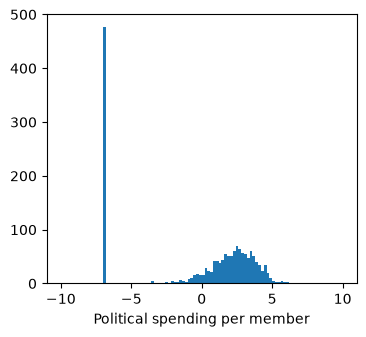

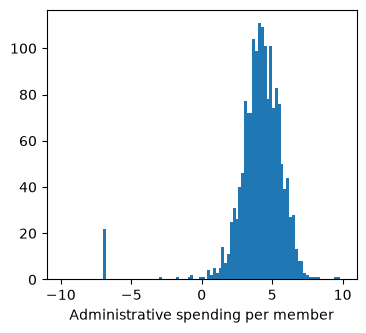

In [14]:
fin['pol_per_mem'] = np.log(fin['political'] / fin['members'] + 0.001)
fin['admin_frac'] = fin['union_administration'] / fin['ttl_disbursements']
fin['admin_per_mem'] = fin['union_administration'] / fin['members']
fin['log_admin_per_mem'] = np.log(fin['admin_per_mem'] + 0.001)

print(f"Median fraction of disbursements spent on admin: {np.median(fin['admin_frac'])}")

plt.figure(figsize=(4, 3.5))
plt.hist(fin['pol_per_mem'], bins=100, range=[-10, 10])
plt.xlabel('Political spending per member')
plt.figure(figsize=(4, 3.5))
plt.hist(fin['log_admin_per_mem'], bins=100, range=[-10, 10])
plt.xlabel('Administrative spending per member')

fin['admin_frac'].describe()

In [61]:
fin[fin['admin_per_mem'] > 1000][['union_administration', 'members', 'admin_per_mem', 'union_participant', 'rpt_id', 'f_num']].sort_values('admin_per_mem', ascending=False)

,union_administration,members,admin_per_mem,union_participant,rpt_id,f_num
2551,717368,11,65215.272727,MID CENTRAL ILLINOIS REGIONAL COUNCIL OF CARPE...,464969,509324
1558,581318,15,38754.533333,LABORERS' INTERNATIONAL UNION OF NORTH AMERICA,452182,31618
3137,255704,11,23245.818182,Public Service Employees Local Union - LIUNA,475423,8146
6415,537874,24,22411.416667,"SOUTH ATLANTIC & GULF COAST DISTRICT, INTERNAT...",532310,17062
13855,3778453,227,16645.167401,THE INTERNATIONAL ALLIANCE OF THEATRICAL STAGE...,866247,31372
2841,286066,20,14303.3,"ASSOCIATED FRENCH SCHOOL EMPLOYEES, AFT, AFL-CIO",467283,512443
8799,137382,14,9813.0,Atomic Projects & Production Workers Metal Tra...,597825,49650
158,281488,64,4398.25,"IATSE, LOCAL 53",694967,22478
7038,141095,40,3527.375,GREAT PLAINS LABORERS' DISTRICT COUNCIL,549094,542992
4353,47798,18,2655.444444,"International Association of Bridge, Structura...",782681,546391


## Success by case type and state

In [63]:
df.groupby("case_type")["net_margin"].agg(["size", "mean"])

,size,mean
case_type,,
RC,21598,0.368279
RM,598,0.104461


In [ ]:
bystate = (
  df.groupby("state")["net_margin"]
    .agg(["size", "mean"])
    .sort_values("size", ascending=False)
)

print(bystate.head(15))

print(bystate.sort_values("mean", ascending=True).head(15))

       size      mean
state                
CA     3179  0.418378
NY     2397  0.412956
IL     1515  0.355265
PA     1398  0.271679
NJ     1042  0.299443
WA      999  0.475865
MI      781  0.275022
MA      776  0.407018
OH      732  0.163419
TX      695  0.365153
OR      612  0.460594
MN      555  0.303954
MD      533  0.446749
CT      484  0.366526
FL      482  0.347137
       size      mean
state                
AR       63  0.098152
SD       17  0.117431
IA      146  0.119956
VI       26  0.153301
OH      732  0.163419
WY       31  0.193611
IN      400  0.207125
AL      126  0.232737
WV      156  0.238547
KY      252  0.244251
MS       62  0.252493
TN      164  0.265867
MO      461  0.266848
PA     1398  0.271679
MI      781  0.275022
       size      mean
state                
GU        7  0.454208
SD       17  0.117431
VI       26  0.153301
ND       27  0.562577
WY       31  0.193611


In [65]:
print(bystate.sort_values('size', ascending=True).head())

       size      mean
state                
GU        7  0.454208
SD       17  0.117431
VI       26  0.153301
ND       27  0.562577
WY       31  0.193611


## Notes

- Vote counts come from the `tally` table (`votes_for_union` /
  `votes_against`). Elections with a contested (>2 option) or only-"No union"
  tally are excluded.
- Elections with zero or missing votes against have an undefined ratio, so
  they are dropped for regression.
- `training.py` loads the same view, collapses it to one row per election, and
  builds the feature/target frames.